# Microcontroller-Based Acoustic-Visual Threat Detection and Evacuation Simulation

## Sto. Niño Senior High School, Tacloban City

Development Environment: Google Colab


## Section 1 — Environment Setup

In [ ]:
import sys

print("Python version:")
print(sys.version)

print("\nGoogle Colab environment is ready.")

Python version:
3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]

Google Colab environment is ready.


In [ ]:
!nvidia-smi

Fri Oct  9 08:58:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q networkx matplotlib pandas

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

print("NetworkX:", nx.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Pandas:", pd.__version__)

print("\nAll required libraries are working.")

NetworkX: 3.7
Matplotlib: 3.10.0
Pandas: 2.2.3

All required libraries are working.


In [ ]:
SCHOOL_NAME = "Sto. Niño Senior High School"
CITY = "Tacloban City"

print("School:", SCHOOL_NAME)
print("Location:", CITY)

School: Sto. Niño Senior High School
Location: Tacloban City


## Section 2 — Sto. Niño SHS Virtual Map

### Building Structure

Building 1: 4 floors, 5 rooms per floor
Building 2: 4 floors, 3 rooms per floor
Building 3: 2 floors, 2 rooms per floor

Total: 36 rooms

In [ ]:
buildings = {
    "B1": {
        "name": "Building 1",
        "floors": 4,
        "rooms_per_floor": 5
    },

    "B2": {
        "name": "Building 2",
        "floors": 4,
        "rooms_per_floor": 3
    },

    "B3": {
        "name": "Building 3",
        "floors": 2,
        "rooms_per_floor": 2
    }
}

print("School buildings:")
for building_id, building in buildings.items():
    print(
        building_id,
        "-",
        building["name"],
        "| Floors:", building["floors"],
        "| Rooms per floor:", building["rooms_per_floor"]
    )

School buildings:
B1 - Building 1 | Floors: 4 | Rooms per floor: 5
B2 - Building 2 | Floors: 4 | Rooms per floor: 3
B3 - Building 3 | Floors: 2 | Rooms per floor: 2


In [ ]:
rooms = []

for building_id, building in buildings.items():
    for floor in range(1, building["floors"] + 1):
        for room in range(1, building["rooms_per_floor"] + 1):
            room_id = f"{building_id}-F{floor}-R{room}"
            rooms.append(room_id)

print("Total rooms:", len(rooms))

Total rooms: 36


In [ ]:
print("Building 1 rooms:")

for room in rooms:
    if room.startswith("B1-"):
        print(room)

Building 1 rooms:
B1-F1-R1
B1-F1-R2
B1-F1-R3
B1-F1-R4
B1-F1-R5
B1-F2-R1
B1-F2-R2
B1-F2-R3
B1-F2-R4
B1-F2-R5
B1-F3-R1
B1-F3-R2
B1-F3-R3
B1-F3-R4
B1-F3-R5
B1-F4-R1
B1-F4-R2
B1-F4-R3
B1-F4-R4
B1-F4-R5


In [ ]:
locations = []

for building_id, building in buildings.items():
    for floor in range(1, building["floors"] + 1):

        corridor = f"{building_id}-F{floor}-CORRIDOR"
        stair_left = f"{building_id}-F{floor}-STAIR-L"
        stair_right = f"{building_id}-F{floor}-STAIR-R"

        locations.append(corridor)
        locations.append(stair_left)
        locations.append(stair_right)

        for room in range(1, building["rooms_per_floor"] + 1):
            room_id = f"{building_id}-F{floor}-R{room}"
            locations.append(room_id)

print("Total locations:", len(locations))

Total locations: 66


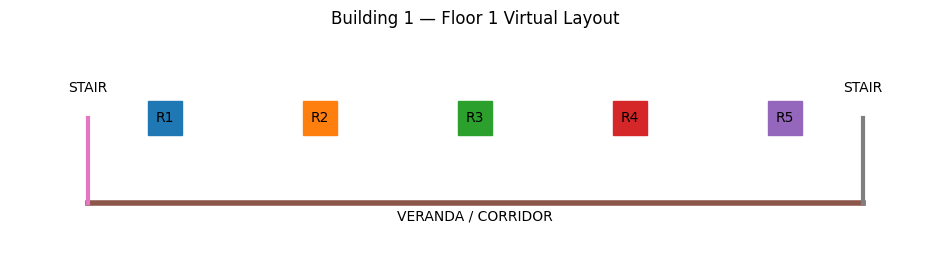

In [ ]:
import matplotlib.pyplot as plt

floor_rooms = [
    "B1-F1-R1",
    "B1-F1-R2",
    "B1-F1-R3",
    "B1-F1-R4",
    "B1-F1-R5"
]

plt.figure(figsize=(12, 3))

for i, room in enumerate(floor_rooms):
    plt.plot(i, 0, "s", markersize=25)
    plt.text(i, 0, f"R{i + 1}", ha="center", va="center")

plt.plot([-0.5, 4.5], [-1, -1], linewidth=4)
plt.text(2, -1.2, "VERANDA / CORRIDOR", ha="center")

plt.plot([-0.5, -0.5], [0, -1], linewidth=3)
plt.text(-0.5, 0.3, "STAIR", ha="center")

plt.plot([4.5, 4.5], [0, -1], linewidth=3)
plt.text(4.5, 0.3, "STAIR", ha="center")

plt.xlim(-1, 5)
plt.ylim(-1.7, 1)
plt.axis("off")
plt.title("Building 1 — Floor 1 Virtual Layout")

plt.show()

In [ ]:
print("Total rooms:", len(rooms))
print("Total locations:", len(locations))

Total rooms: 36
Total locations: 66


## Section 3 — School Graph and Connections

In [ ]:
school_graph = nx.Graph()

print("School graph created.")

School graph created.


In [ ]:
school_graph.add_nodes_from(locations)

print("Total graph locations:", school_graph.number_of_nodes())

Total graph locations: 66


In [ ]:
for building_id, building in buildings.items():

    for floor in range(1, building["floors"] + 1):

        corridor = f"{building_id}-F{floor}-CORRIDOR"

        for room in range(1, building["rooms_per_floor"] + 1):

            room_id = f"{building_id}-F{floor}-R{room}"

            school_graph.add_edge(
                room_id,
                corridor,
                weight=1
            )

print("Room-to-corridor connections added.")

Room-to-corridor connections added.


In [ ]:
for building_id, building in buildings.items():

    for floor in range(1, building["floors"] + 1):

        corridor = f"{building_id}-F{floor}-CORRIDOR"

        stair_left = f"{building_id}-F{floor}-STAIR-L"
        stair_right = f"{building_id}-F{floor}-STAIR-R"

        school_graph.add_edge(
            corridor,
            stair_left,
            weight=1
        )

        school_graph.add_edge(
            corridor,
            stair_right,
            weight=1
        )

print("Corridor-to-stair connections added.")

Corridor-to-stair connections added.


In [ ]:
for building_id, building in buildings.items():

    for floor in range(1, building["floors"]):

        current_left = f"{building_id}-F{floor}-STAIR-L"
        next_left = f"{building_id}-F{floor + 1}-STAIR-L"

        current_right = f"{building_id}-F{floor}-STAIR-R"
        next_right = f"{building_id}-F{floor + 1}-STAIR-R"

        school_graph.add_edge(
            current_left,
            next_left,
            weight=1
        )

        school_graph.add_edge(
            current_right,
            next_right,
            weight=1
        )

print("Vertical staircase connections added.")

Vertical staircase connections added.


In [ ]:
print("Total locations:", school_graph.number_of_nodes())
print("Total connections:", school_graph.number_of_edges())

Total locations: 66
Total connections: 70


In [ ]:
for building_id, building in buildings.items():

    building_nodes = [
        node for node in school_graph.nodes
        if node.startswith(building_id + "-")
    ]

    building_graph = school_graph.subgraph(building_nodes)

    print(
        building["name"],
        "connected:",
        nx.is_connected(building_graph)
    )

Building 1 connected: True
Building 2 connected: True
Building 3 connected: True


In [ ]:
components = list(nx.connected_components(school_graph))

print("Connected components:", len(components))

for i, component in enumerate(components, start=1):
    print(f"Component {i}: {len(component)} locations")

Connected components: 3
Component 1: 32 locations
Component 2: 24 locations
Component 3: 10 locations


In [ ]:
start = "B1-F4-R3"
destination = "B1-F1-R1"

route = nx.shortest_path(
    school_graph,
    start,
    destination,
    weight="weight"
)

print("Route:")

for location in route:
    print(location)

Route:
B1-F4-R3
B1-F4-CORRIDOR
B1-F4-STAIR-L
B1-F3-STAIR-L
B1-F2-STAIR-L
B1-F1-STAIR-L
B1-F1-CORRIDOR
B1-F1-R1


In [ ]:
start = "B2-F4-R3"
destination = "B2-F1-R1"

route = nx.shortest_path(
    school_graph,
    start,
    destination,
    weight="weight"
)

print("Route:")

for location in route:
    print(location)

Route:
B2-F4-R3
B2-F4-CORRIDOR
B2-F4-STAIR-L
B2-F3-STAIR-L
B2-F2-STAIR-L
B2-F1-STAIR-L
B2-F1-CORRIDOR
B2-F1-R1


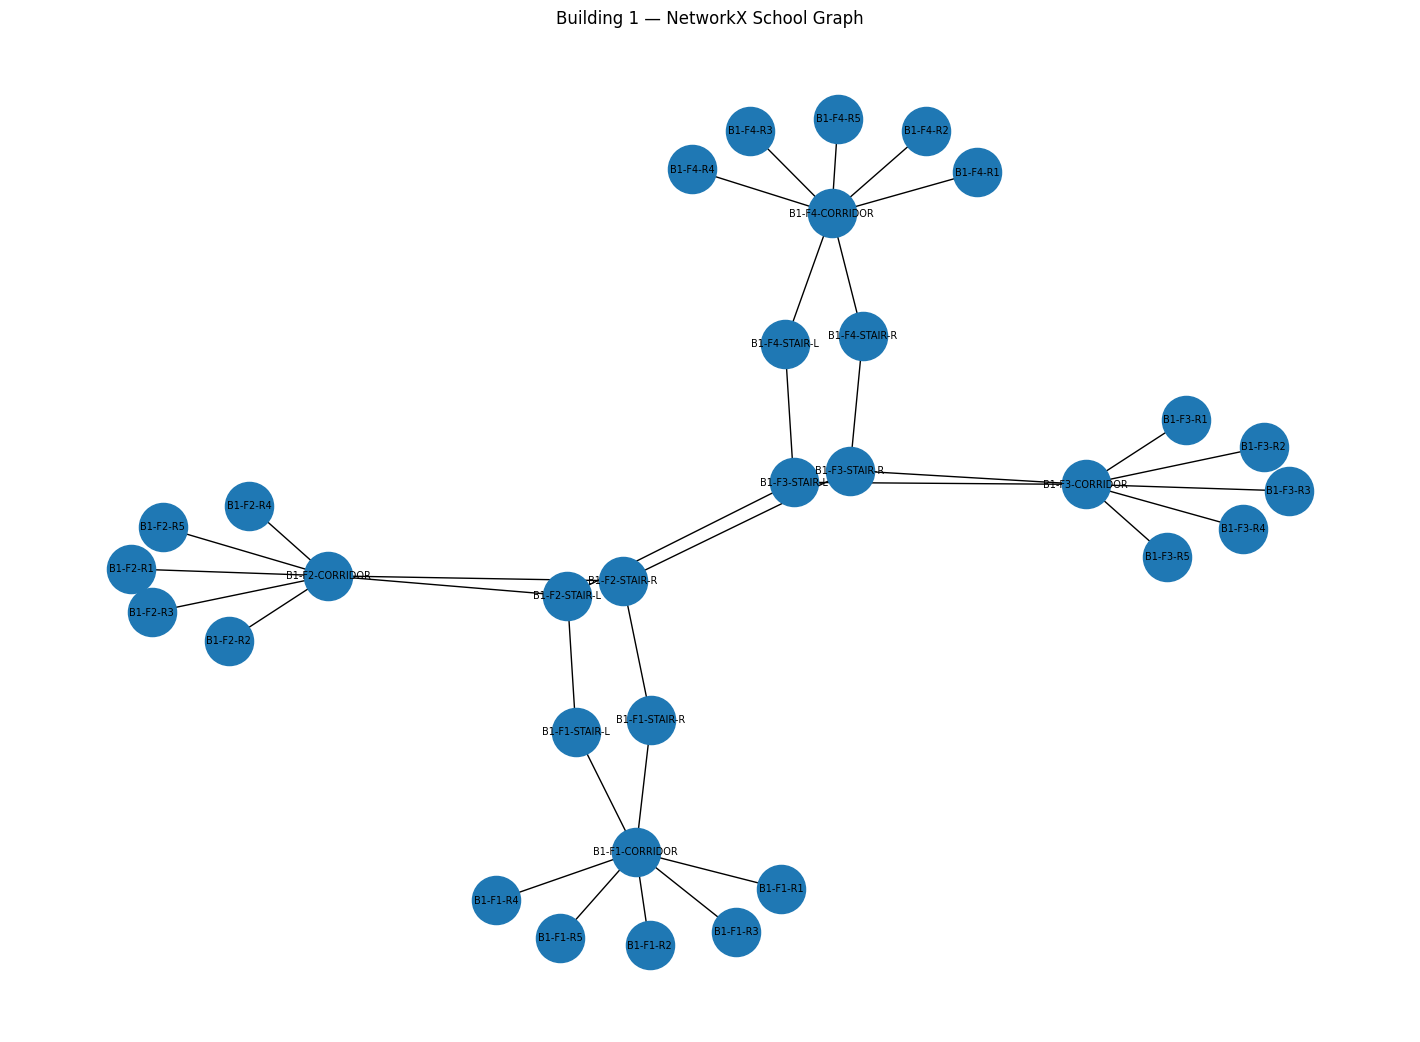

In [ ]:
building_1_nodes = [
    node for node in school_graph.nodes
    if node.startswith("B1-")
]

building_1_graph = school_graph.subgraph(building_1_nodes)

plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    building_1_graph,
    seed=42
)

nx.draw(
    building_1_graph,
    pos,
    with_labels=True,
    node_size=1200,
    font_size=7
)

plt.title("Building 1 — NetworkX School Graph")
plt.show()

## Section 4 — Route Finding

In [ ]:
def find_route(start, destination):
    try:
        route = nx.shortest_path(
            school_graph,
            start,
            destination,
            weight="weight"
        )

        distance = nx.shortest_path_length(
            school_graph,
            start,
            destination,
            weight="weight"
        )

        return route, distance

    except nx.NetworkXNoPath:
        return None, None

In [ ]:
find_route("B1-F4-R3", "B1-F1-R1")

(['B1-F4-R3',
  'B1-F4-CORRIDOR',
  'B1-F4-STAIR-L',
  'B1-F3-STAIR-L',
  'B1-F2-STAIR-L',
  'B1-F1-STAIR-L',
  'B1-F1-CORRIDOR',
  'B1-F1-R1'],
 7)

In [ ]:
start = "B1-F4-R3"
destination = "B1-F1-R1"

route, distance = find_route(start, destination)

print("Start:", start)
print("Destination:", destination)
print("Distance:", distance)

print("\nRoute:")
for location in route:
    print("→", location)

Start: B1-F4-R3
Destination: B1-F1-R1
Distance: 7

Route:
→ B1-F4-R3
→ B1-F4-CORRIDOR
→ B1-F4-STAIR-L
→ B1-F3-STAIR-L
→ B1-F2-STAIR-L
→ B1-F1-STAIR-L
→ B1-F1-CORRIDOR
→ B1-F1-R1


In [ ]:
def show_route(start, destination):
    route, distance = find_route(start, destination)

    if route is None:
        print("No available route.")
        return

    print("================================")
    print("ROUTE INFORMATION")
    print("================================")
    print("Start:", start)
    print("Destination:", destination)
    print("Number of steps:", distance)

    print("\nPath:")

    for i, location in enumerate(route, start=1):
        print(f"{i}. {location}")

In [ ]:
show_route("B1-F4-R3", "B1-F1-R1")

ROUTE INFORMATION
Start: B1-F4-R3
Destination: B1-F1-R1
Number of steps: 7

Path:
1. B1-F4-R3
2. B1-F4-CORRIDOR
3. B1-F4-STAIR-L
4. B1-F3-STAIR-L
5. B1-F2-STAIR-L
6. B1-F1-STAIR-L
7. B1-F1-CORRIDOR
8. B1-F1-R1


In [ ]:
show_route("B1-F1-R1", "B1-F4-R5")

ROUTE INFORMATION
Start: B1-F1-R1
Destination: B1-F4-R5
Number of steps: 7

Path:
1. B1-F1-R1
2. B1-F1-CORRIDOR
3. B1-F1-STAIR-L
4. B1-F2-STAIR-L
5. B1-F3-STAIR-L
6. B1-F4-STAIR-L
7. B1-F4-CORRIDOR
8. B1-F4-R5


In [ ]:
show_route("B1-F1-R1", "B2-F1-R1")

No available route.


## Section 5 — Threat Simulation

### Purpose

This section simulates a detected potential threat at a selected
school location. The threat is manually assigned for testing.
No AI detection is used yet.

In [ ]:
threat_location = "B1-F2-R3"

print("Simulated threat location:", threat_location)

Simulated threat location: B1-F2-R3


In [ ]:
if threat_location in school_graph:
    print("Threat location exists in the school graph.")
else:
    print("ERROR: Threat location does not exist.")

Threat location exists in the school graph.


In [ ]:
affected_locations = [
    threat_location,
    "B1-F2-CORRIDOR"
]

print("Affected locations:")

for location in affected_locations:
    print("-", location)

Affected locations:
- B1-F2-R3
- B1-F2-CORRIDOR


In [ ]:
threat_graph = school_graph.copy()

for location in affected_locations:
    threat_graph.remove_node(location)

print("Original graph locations:", school_graph.number_of_nodes())
print("Threat graph locations:", threat_graph.number_of_nodes())

Original graph locations: 66
Threat graph locations: 64


In [ ]:
print(
    "Original graph connections:",
    school_graph.number_of_edges()
)

print(
    "Threat graph connections:",
    threat_graph.number_of_edges()
)

Original graph connections: 70
Threat graph connections: 63


In [ ]:
def find_route_on_graph(graph, start, destination):
    try:
        route = nx.shortest_path(
            graph,
            start,
            destination,
            weight="weight"
        )

        distance = nx.shortest_path_length(
            graph,
            start,
            destination,
            weight="weight"
        )

        return route, distance

    except nx.NetworkXNoPath:
        return None, None

In [ ]:
start = "B1-F4-R3"
destination = "B1-F1-R1"

route, distance = find_route_on_graph(
    school_graph,
    start,
    destination
)

print("NORMAL ROUTE")
print("Start:", start)
print("Destination:", destination)
print("Distance:", distance)

for location in route:
    print("→", location)

NORMAL ROUTE
Start: B1-F4-R3
Destination: B1-F1-R1
Distance: 7
→ B1-F4-R3
→ B1-F4-CORRIDOR
→ B1-F4-STAIR-L
→ B1-F3-STAIR-L
→ B1-F2-STAIR-L
→ B1-F1-STAIR-L
→ B1-F1-CORRIDOR
→ B1-F1-R1


In [ ]:
route, distance = find_route_on_graph(
    threat_graph,
    start,
    destination
)

print("ROUTE AFTER THREAT")
print("Start:", start)
print("Destination:", destination)

if route is None:
    print("No available route.")
else:
    print("Distance:", distance)

    for location in route:
        print("→", location)

ROUTE AFTER THREAT
Start: B1-F4-R3
Destination: B1-F1-R1
Distance: 7
→ B1-F4-R3
→ B1-F4-CORRIDOR
→ B1-F4-STAIR-L
→ B1-F3-STAIR-L
→ B1-F2-STAIR-L
→ B1-F1-STAIR-L
→ B1-F1-CORRIDOR
→ B1-F1-R1


In [ ]:
print("Threat room in graph:", threat_location in threat_graph)
print(
    "Threat corridor in graph:",
    "B1-F2-CORRIDOR" in threat_graph
)

Threat room in graph: False
Threat corridor in graph: False


In [ ]:
def simulate_threat(threat_location):
    if threat_location not in school_graph:
        print("ERROR: Threat location does not exist.")
        return None, []

    parts = threat_location.split("-")

    building = parts[0]
    floor = parts[1]

    corridor = f"{building}-{floor}-CORRIDOR"

    affected_locations = [
        threat_location,
        corridor
    ]

    modified_graph = school_graph.copy()

    for location in affected_locations:
        if location in modified_graph:
            modified_graph.remove_node(location)

    return modified_graph, affected_locations

In [ ]:
threat_graph, affected_locations = simulate_threat("B1-F2-R3")

print("Threat:", "B1-F2-R3")

print("\nAffected locations:")

for location in affected_locations:
    print("-", location)

Threat: B1-F2-R3

Affected locations:
- B1-F2-R3
- B1-F2-CORRIDOR


In [ ]:
threat_graph, affected_locations = simulate_threat("B2-F3-R2")

print("Threat:", "B2-F3-R2")

print("\nAffected locations:")

for location in affected_locations:
    print("-", location)

Threat: B2-F3-R2

Affected locations:
- B2-F3-R2
- B2-F3-CORRIDOR


## Section 6 — Dynamic Route Recalculation

### Purpose

This section compares the normal route with the route available
after a simulated threat blocks an affected area.

In [ ]:
def find_route_on_graph(graph, start, destination):
    try:
        route = nx.shortest_path(
            graph,
            start,
            destination,
            weight="weight"
        )

        distance = nx.shortest_path_length(
            graph,
            start,
            destination,
            weight="weight"
        )

        return route, distance

    except nx.NetworkXNoPath:
        return None, None

In [ ]:
def simulate_threat(threat_location):
    if threat_location not in school_graph:
        print("ERROR: Threat location does not exist.")
        return None, []

    affected_locations = [threat_location]

    modified_graph = school_graph.copy()
    modified_graph.remove_node(threat_location)

    return modified_graph, affected_locations

In [ ]:
test_graph, affected_locations = simulate_threat("B1-F2-R3")

print("Affected locations:")

for location in affected_locations:
    print("-", location)

Affected locations:
- B1-F2-R3


In [ ]:
route, distance = find_route_on_graph(
    school_graph,
    "B1-F4-R3",
    "B1-F1-R1"
)

print("Distance:", distance)

for location in route:
    print("→", location)

Distance: 7
→ B1-F4-R3
→ B1-F4-CORRIDOR
→ B1-F4-STAIR-L
→ B1-F3-STAIR-L
→ B1-F2-STAIR-L
→ B1-F1-STAIR-L
→ B1-F1-CORRIDOR
→ B1-F1-R1


In [ ]:
def compare_routes(start, destination, threat_location):

    print("================================")
    print("ROUTE COMPARISON")
    print("================================")

    print("\nStart:", start)
    print("Destination:", destination)
    print("Threat:", threat_location)

    # Find the normal route
    try:
        normal_route = nx.shortest_path(
            school_graph,
            start,
            destination,
            weight="weight"
        )

        normal_distance = nx.shortest_path_length(
            school_graph,
            start,
            destination,
            weight="weight"
        )

    except nx.NetworkXNoPath:
        normal_route = None
        normal_distance = None

    except nx.NodeNotFound:
        normal_route = None
        normal_distance = None

    # Create the modified graph
    threat_graph, affected_locations = simulate_threat(
        threat_location
    )

    print("\nAffected locations:")

    for location in affected_locations:
        print("-", location)

    # Show normal route
    print("\nNormal route:")

    if normal_route is not None:

        for location in normal_route:
            print("→", location)

        print("Distance:", normal_distance)

    else:
        print("No normal route.")

    # Check whether start or destination was affected
    if start in affected_locations:
        print("\nRoute after threat:")
        print("Cannot calculate route.")
        print("The starting location is inside the affected area.")
        return

    if destination in affected_locations:
        print("\nRoute after threat:")
        print("Cannot calculate route.")
        print("The destination is inside the affected area.")
        return

    # Find alternative route
    try:
        alternative_route = nx.shortest_path(
            threat_graph,
            start,
            destination,
            weight="weight"
        )

        alternative_distance = nx.shortest_path_length(
            threat_graph,
            start,
            destination,
            weight="weight"
        )

    except nx.NetworkXNoPath:
        alternative_route = None
        alternative_distance = None

    except nx.NodeNotFound:
        alternative_route = None
        alternative_distance = None

    print("\nRoute after threat:")

    if alternative_route is not None:

        for location in alternative_route:
            print("→", location)

        print("Distance:", alternative_distance)

    else:
        print("No available route.")

In [ ]:
compare_routes(
    "B1-F4-R3",
    "B1-F1-R1",
    "B1-F2-R3"
)

ROUTE COMPARISON

Start: B1-F4-R3
Destination: B1-F1-R1
Threat: B1-F2-R3

Affected locations:
- B1-F2-R3

Normal route:
→ B1-F4-R3
→ B1-F4-CORRIDOR
→ B1-F4-STAIR-L
→ B1-F3-STAIR-L
→ B1-F2-STAIR-L
→ B1-F1-STAIR-L
→ B1-F1-CORRIDOR
→ B1-F1-R1
Distance: 7

Route after threat:
→ B1-F4-R3
→ B1-F4-CORRIDOR
→ B1-F4-STAIR-L
→ B1-F3-STAIR-L
→ B1-F2-STAIR-L
→ B1-F1-STAIR-L
→ B1-F1-CORRIDOR
→ B1-F1-R1
Distance: 7


In [ ]:
compare_routes(
    "B2-F4-R3",
    "B2-F1-R1",
    "B2-F3-R2"
)

ROUTE COMPARISON

Start: B2-F4-R3
Destination: B2-F1-R1
Threat: B2-F3-R2

Affected locations:
- B2-F3-R2

Normal route:
→ B2-F4-R3
→ B2-F4-CORRIDOR
→ B2-F4-STAIR-L
→ B2-F3-STAIR-L
→ B2-F2-STAIR-L
→ B2-F1-STAIR-L
→ B2-F1-CORRIDOR
→ B2-F1-R1
Distance: 7

Route after threat:
→ B2-F4-R3
→ B2-F4-CORRIDOR
→ B2-F4-STAIR-L
→ B2-F3-STAIR-L
→ B2-F2-STAIR-L
→ B2-F1-STAIR-L
→ B2-F1-CORRIDOR
→ B2-F1-R1
Distance: 7


In [ ]:
compare_routes(
    "B3-F2-R1",
    "B3-F1-R2",
    "B3-F2-R2" # Changed threat_location to avoid removing the start node
)

ROUTE COMPARISON

Start: B3-F2-R1
Destination: B3-F1-R2
Threat: B3-F2-R2

Affected locations:
- B3-F2-R2

Normal route:
→ B3-F2-R1
→ B3-F2-CORRIDOR
→ B3-F2-STAIR-L
→ B3-F1-STAIR-L
→ B3-F1-CORRIDOR
→ B3-F1-R2
Distance: 5

Route after threat:
→ B3-F2-R1
→ B3-F2-CORRIDOR
→ B3-F2-STAIR-L
→ B3-F1-STAIR-L
→ B3-F1-CORRIDOR
→ B3-F1-R2
Distance: 5


In [ ]:
compare_routes(
    "B3-F2-R2",
    "B3-F1-R1",
    "B3-F2-R1"
)

ROUTE COMPARISON

Start: B3-F2-R2
Destination: B3-F1-R1
Threat: B3-F2-R1

Affected locations:
- B3-F2-R1

Normal route:
→ B3-F2-R2
→ B3-F2-CORRIDOR
→ B3-F2-STAIR-L
→ B3-F1-STAIR-L
→ B3-F1-CORRIDOR
→ B3-F1-R1
Distance: 5

Route after threat:
→ B3-F2-R2
→ B3-F2-CORRIDOR
→ B3-F2-STAIR-L
→ B3-F1-STAIR-L
→ B3-F1-CORRIDOR
→ B3-F1-R1
Distance: 5


In [ ]:
compare_routes(
    "B3-F2-R2",
    "B3-F1-R1",
    "B3-F2-R1"
)

ROUTE COMPARISON

Start: B3-F2-R2
Destination: B3-F1-R1
Threat: B3-F2-R1

Affected locations:
- B3-F2-R1

Normal route:
→ B3-F2-R2
→ B3-F2-CORRIDOR
→ B3-F2-STAIR-L
→ B3-F1-STAIR-L
→ B3-F1-CORRIDOR
→ B3-F1-R1
Distance: 5

Route after threat:
→ B3-F2-R2
→ B3-F2-CORRIDOR
→ B3-F2-STAIR-L
→ B3-F1-STAIR-L
→ B3-F1-CORRIDOR
→ B3-F1-R1
Distance: 5


In [ ]:
test_graph, affected_locations = simulate_threat("B3-F2-R1")

print("Affected locations:")

for location in affected_locations:
    print("-", location)

print("\nThreat room in graph:")
print("B3-F2-R1" in test_graph)

print("\nThreat corridor in graph:")
print("B3-F2-CORRIDOR" in test_graph)

Affected locations:
- B3-F2-R1

Threat room in graph:
False

Threat corridor in graph:
True


In [ ]:
compare_routes(
    "B3-F2-R2",
    "B3-F1-R1",
    "B3-F2-R1"
)

ROUTE COMPARISON

Start: B3-F2-R2
Destination: B3-F1-R1
Threat: B3-F2-R1

Affected locations:
- B3-F2-R1

Normal route:
→ B3-F2-R2
→ B3-F2-CORRIDOR
→ B3-F2-STAIR-L
→ B3-F1-STAIR-L
→ B3-F1-CORRIDOR
→ B3-F1-R1
Distance: 5

Route after threat:
→ B3-F2-R2
→ B3-F2-CORRIDOR
→ B3-F2-STAIR-L
→ B3-F1-STAIR-L
→ B3-F1-CORRIDOR
→ B3-F1-R1
Distance: 5


In [ ]:
compare_routes(
    "B3-F2-R1",
    "B3-F1-R2",
    "B3-F2-R1"
)

ROUTE COMPARISON

Start: B3-F2-R1
Destination: B3-F1-R2
Threat: B3-F2-R1

Affected locations:
- B3-F2-R1

Normal route:
→ B3-F2-R1
→ B3-F2-CORRIDOR
→ B3-F2-STAIR-L
→ B3-F1-STAIR-L
→ B3-F1-CORRIDOR
→ B3-F1-R2
Distance: 5

Route after threat:
Cannot calculate route.
The starting location is inside the affected area.


In [ ]:
print("School graph loaded:", "school_graph" in globals())

if "school_graph" in globals():
    print("Locations:", school_graph.number_of_nodes())
    print("Connections:", school_graph.number_of_edges())

School graph loaded: True
Locations: 66
Connections: 70


In [ ]:
test_graph, affected_locations = simulate_threat("B3-F2-R1")

print("Affected locations:")
for location in affected_locations:
    print("-", location)

print("\nThreat room in graph:")
print("B3-F2-R1" in test_graph)

print("\nThreat corridor in graph:")
print("B3-F2-CORRIDOR" in test_graph)

Affected locations:
- B3-F2-R1

Threat room in graph:
False

Threat corridor in graph:
True


In [ ]:
compare_routes(
    "B3-F2-R2",
    "B3-F1-R1",
    "B3-F2-R1"
)

ROUTE COMPARISON

Start: B3-F2-R2
Destination: B3-F1-R1
Threat: B3-F2-R1

Affected locations:
- B3-F2-R1

Normal route:
→ B3-F2-R2
→ B3-F2-CORRIDOR
→ B3-F2-STAIR-L
→ B3-F1-STAIR-L
→ B3-F1-CORRIDOR
→ B3-F1-R1
Distance: 5

Route after threat:
→ B3-F2-R2
→ B3-F2-CORRIDOR
→ B3-F2-STAIR-L
→ B3-F1-STAIR-L
→ B3-F1-CORRIDOR
→ B3-F1-R1
Distance: 5


In [ ]:
start = "B3-F2-R2"
destination = "B3-F1-R1"
threat = "B3-F2-CORRIDOR"

compare_routes(start, destination, threat)

ROUTE COMPARISON

Start: B3-F2-R2
Destination: B3-F1-R1
Threat: B3-F2-CORRIDOR

Affected locations:
- B3-F2-CORRIDOR

Normal route:
→ B3-F2-R2
→ B3-F2-CORRIDOR
→ B3-F2-STAIR-L
→ B3-F1-STAIR-L
→ B3-F1-CORRIDOR
→ B3-F1-R1
Distance: 5

Route after threat:
No available route.


In [ ]:
start = "B1-F4-R3"
destination = "B1-F1-R1"
threat = "B1-F4-CORRIDOR"

compare_routes(start, destination, threat)

ROUTE COMPARISON

Start: B1-F4-R3
Destination: B1-F1-R1
Threat: B1-F4-CORRIDOR

Affected locations:
- B1-F4-CORRIDOR

Normal route:
→ B1-F4-R3
→ B1-F4-CORRIDOR
→ B1-F4-STAIR-L
→ B1-F3-STAIR-L
→ B1-F2-STAIR-L
→ B1-F1-STAIR-L
→ B1-F1-CORRIDOR
→ B1-F1-R1
Distance: 7

Route after threat:
No available route.


In [ ]:
start = "B1-F4-R3"
destination = "B1-F1-R1"
threat = "B1-F4-STAIR-L"

compare_routes(start, destination, threat)

ROUTE COMPARISON

Start: B1-F4-R3
Destination: B1-F1-R1
Threat: B1-F4-STAIR-L

Affected locations:
- B1-F4-STAIR-L

Normal route:
→ B1-F4-R3
→ B1-F4-CORRIDOR
→ B1-F4-STAIR-L
→ B1-F3-STAIR-L
→ B1-F2-STAIR-L
→ B1-F1-STAIR-L
→ B1-F1-CORRIDOR
→ B1-F1-R1
Distance: 7

Route after threat:
→ B1-F4-R3
→ B1-F4-CORRIDOR
→ B1-F4-STAIR-R
→ B1-F3-STAIR-R
→ B1-F2-STAIR-R
→ B1-F1-STAIR-R
→ B1-F1-CORRIDOR
→ B1-F1-R1
Distance: 7


In [ ]:
simulate_threat(threat_location)

(<networkx.classes.graph.Graph at 0x7d5a66c66cf0>, ['B1-F2-R3'])

In [ ]:
test_graph, affected_locations = simulate_threat("B1-F2-R3")

print("Affected locations:")
for location in affected_locations:
    print("-", location)

print("\nIs the threat room still in the graph?")
print("B1-F2-R3" in test_graph)

print("\nIs the corridor still in the graph?")
print("B1-F2-CORRIDOR" in test_graph)

Affected locations:
- B1-F2-R3

Is the threat room still in the graph?
False

Is the corridor still in the graph?
True


In [ ]:
compare_routes(
    "B1-F4-R3",
    "B1-F1-R1",
    "B1-F2-R3"
)

ROUTE COMPARISON

Start: B1-F4-R3
Destination: B1-F1-R1
Threat: B1-F2-R3

Affected locations:
- B1-F2-R3

Normal route:
→ B1-F4-R3
→ B1-F4-CORRIDOR
→ B1-F4-STAIR-L
→ B1-F3-STAIR-L
→ B1-F2-STAIR-L
→ B1-F1-STAIR-L
→ B1-F1-CORRIDOR
→ B1-F1-R1
Distance: 7

Route after threat:
→ B1-F4-R3
→ B1-F4-CORRIDOR
→ B1-F4-STAIR-L
→ B1-F3-STAIR-L
→ B1-F2-STAIR-L
→ B1-F1-STAIR-L
→ B1-F1-CORRIDOR
→ B1-F1-R1
Distance: 7


In [ ]:
compare_routes(
    "B1-F4-R3",
    "B1-F1-R1",
    "B1-F3-STAIR-L"
)

ROUTE COMPARISON

Start: B1-F4-R3
Destination: B1-F1-R1
Threat: B1-F3-STAIR-L

Affected locations:
- B1-F3-STAIR-L

Normal route:
→ B1-F4-R3
→ B1-F4-CORRIDOR
→ B1-F4-STAIR-L
→ B1-F3-STAIR-L
→ B1-F2-STAIR-L
→ B1-F1-STAIR-L
→ B1-F1-CORRIDOR
→ B1-F1-R1
Distance: 7

Route after threat:
→ B1-F4-R3
→ B1-F4-CORRIDOR
→ B1-F4-STAIR-R
→ B1-F3-STAIR-R
→ B1-F2-STAIR-R
→ B1-F1-STAIR-R
→ B1-F1-CORRIDOR
→ B1-F1-R1
Distance: 7


In [ ]:
test_graph, affected_locations = simulate_threat("B1-F1-CORRIDOR")

print("Affected locations:", affected_locations)

route = find_route_on_graph(
    test_graph,
    "B1-F4-R3",
    "B1-F1-R1"
)

print("\nRoute after threat:")
print(route)


Affected locations: ['B1-F1-CORRIDOR']

Route after threat:
(None, None)


In [ ]:
test_graph, affected_locations = simulate_threat("B1-F1-CORRIDOR")

route, distance = find_route_on_graph(
    test_graph,
    "B1-F4-R3",
    "B1-F1-R1"
)

if route is None:
    print("STATUS: NO ALTERNATIVE ROUTE")
    print("The destination is unreachable.")
else:
    print("STATUS: ALTERNATIVE ROUTE FOUND")
    print("Route:", route)
    print("Distance:", distance)

STATUS: NO ALTERNATIVE ROUTE
The destination is unreachable.


In [ ]:

def get_evacuation_result(start, destination, threat_location):
    test_graph, affected_locations = simulate_threat(threat_location)

    normal_route, normal_distance = find_route_on_graph(
        school_graph,
        start,
        destination
    )

    if start not in test_graph or destination not in test_graph:
        safe_route = None
        safe_distance = None
    else:
        safe_route, safe_distance = find_route_on_graph(
            test_graph,
            start,
            destination
        )

    if safe_route is None:
        status = "NO ALTERNATIVE ROUTE"
    else:
        status = "ALTERNATIVE ROUTE FOUND"

    return {
        "start": start,
        "destination": destination,
        "threat_location": threat_location,
        "affected_locations": affected_locations,
        "normal_route": normal_route,
        "normal_distance": normal_distance,
        "safe_route": safe_route,
        "safe_distance": safe_distance,
        "status": status
    }

In [ ]:

result = get_evacuation_result(
    "B1-F4-R3",
    "B1-F1-R1",
    "B1-F1-CORRIDOR"
)

for key, value in result.items():
    print(key, ":", value)

start : B1-F4-R3
destination : B1-F1-R1
threat_location : B1-F1-CORRIDOR
affected_locations : ['B1-F1-CORRIDOR']
normal_route : ['B1-F4-R3', 'B1-F4-CORRIDOR', 'B1-F4-STAIR-L', 'B1-F3-STAIR-L', 'B1-F2-STAIR-L', 'B1-F1-STAIR-L', 'B1-F1-CORRIDOR', 'B1-F1-R1']
normal_distance : 7
safe_route : None
safe_distance : None
status : NO ALTERNATIVE ROUTE


In [ ]:

test_cases = [
    {
        "name": "Threat in a room",
        "start": "B1-F4-R3",
        "destination": "B1-F1-R1",
        "threat": "B1-F3-R3"
    },
    {
        "name": "Threat on a stairway",
        "start": "B1-F4-R3",
        "destination": "B1-F1-R1",
        "threat": "B1-F3-STAIR-L"
    },
    {
        "name": "Threat blocking a corridor",
        "start": "B1-F4-R3",
        "destination": "B1-F1-R1",
        "threat": "B1-F1-CORRIDOR"
    }
]

for test in test_cases:
    print("\n==============================")
    print(test["name"])
    print("==============================")

    try:
        result = get_evacuation_result(
            test["start"],
            test["destination"],
            test["threat"]
        )

        print("Threat:", result["threat_location"])
        print("Affected:", result["affected_locations"])
        print("Normal distance:", result["normal_distance"])
        print("Adjusted route:", result["safe_route"])
        print("Adjusted distance:", result["safe_distance"])
        print("Status:", result["status"])

    except Exception as error:
        print("TEST ERROR:", error)


Threat in a room
Threat: B1-F3-R3
Affected: ['B1-F3-R3']
Normal distance: 7
Adjusted route: ['B1-F4-R3', 'B1-F4-CORRIDOR', 'B1-F4-STAIR-L', 'B1-F3-STAIR-L', 'B1-F2-STAIR-L', 'B1-F1-STAIR-L', 'B1-F1-CORRIDOR', 'B1-F1-R1']
Adjusted distance: 7
Status: ALTERNATIVE ROUTE FOUND

Threat on a stairway
Threat: B1-F3-STAIR-L
Affected: ['B1-F3-STAIR-L']
Normal distance: 7
Adjusted route: ['B1-F4-R3', 'B1-F4-CORRIDOR', 'B1-F4-STAIR-R', 'B1-F3-STAIR-R', 'B1-F2-STAIR-R', 'B1-F1-STAIR-R', 'B1-F1-CORRIDOR', 'B1-F1-R1']
Adjusted distance: 7
Status: ALTERNATIVE ROUTE FOUND

Threat blocking a corridor
Threat: B1-F1-CORRIDOR
Affected: ['B1-F1-CORRIDOR']
Normal distance: 7
Adjusted route: None
Adjusted distance: None
Status: NO ALTERNATIVE ROUTE


In [ ]:

def display_evacuation_summary(result):
    print("CAMPUS SENTINEL AI")
    print("EVACUATION ROUTE SUMMARY")
    print("-" * 35)

    print("Starting point:", result["start"])
    print("Destination:", result["destination"])
    print("Threat location:", result["threat_location"])
    print("Affected locations:", result["affected_locations"])

    print("\nNORMAL ROUTE")
    if result["normal_route"] is None:
        print("No normal route available.")
    else:
        print(" -> ".join(result["normal_route"]))
        print("Distance:", result["normal_distance"])

    print("\nTHREAT-ADJUSTED ROUTE")
    if result["safe_route"] is None:
        print("NO ALTERNATIVE ROUTE")
        print("Destination is unreachable in the simulated graph.")
    else:
        print(" -> ".join(result["safe_route"]))
        print("Distance:", result["safe_distance"])

    print("\nROUTING STATUS:", result["status"])
    print("-" * 35)

In [ ]:

result = get_evacuation_result(
    "B1-F4-R3",
    "B1-F1-R1",
    "B1-F1-CORRIDOR"
)

display_evacuation_summary(result)


CAMPUS SENTINEL AI
EVACUATION ROUTE SUMMARY
-----------------------------------
Starting point: B1-F4-R3
Destination: B1-F1-R1
Threat location: B1-F1-CORRIDOR
Affected locations: ['B1-F1-CORRIDOR']

NORMAL ROUTE
B1-F4-R3 -> B1-F4-CORRIDOR -> B1-F4-STAIR-L -> B1-F3-STAIR-L -> B1-F2-STAIR-L -> B1-F1-STAIR-L -> B1-F1-CORRIDOR -> B1-F1-R1
Distance: 7

THREAT-ADJUSTED ROUTE
NO ALTERNATIVE ROUTE
Destination is unreachable in the simulated graph.

ROUTING STATUS: NO ALTERNATIVE ROUTE
-----------------------------------


In [ ]:

!pip -q install gradio

In [ ]:

print("ORIGINAL GRAPH")
print("Nodes:", school_graph.number_of_nodes())
print("Start exists:", "B1-F4-R3" in school_graph)
print("Destination exists:", "B1-F1-R1" in school_graph)

test_graph, affected_locations = simulate_threat(
    "B1-F1-CORRIDOR"
)

print("\nTHREAT-ADJUSTED GRAPH")
print("Nodes:", test_graph.number_of_nodes())
print("Start exists:", "B1-F4-R3" in test_graph)
print("Destination exists:", "B1-F1-R1" in test_graph)

print("\nDIRECT ROUTE TEST")
try:
    print(find_route_on_graph(
        school_graph,
        "B1-F4-R3",
        "B1-F1-R1"
    ))
except Exception as error:
    print(type(error).__name__, error)

ORIGINAL GRAPH
Nodes: 66
Start exists: True
Destination exists: True

THREAT-ADJUSTED GRAPH
Nodes: 65
Start exists: True
Destination exists: True

DIRECT ROUTE TEST
(['B1-F4-R3', 'B1-F4-CORRIDOR', 'B1-F4-STAIR-L', 'B1-F3-STAIR-L', 'B1-F2-STAIR-L', 'B1-F1-STAIR-L', 'B1-F1-CORRIDOR', 'B1-F1-R1'], 7)


In [ ]:

def calculate_threat_index(acoustic, pose, object_detection):
    scores = {
        "acoustic": acoustic,
        "pose": pose,
        "object_detection": object_detection
    }

    for name, score in scores.items():
        if not isinstance(score, (int, float)):
            raise ValueError(name + " must be a number")

        if score < 0 or score > 100:
            raise ValueError(name + " must be between 0 and 100")

    threat_index = (
        acoustic * 0.25
        + pose * 0.30
        + object_detection * 0.45
    )

    supporting_signals = sum(
        1 for score in scores.values()
        if score >= 50
    )

    verified = (
        object_detection >= 60
        and supporting_signals >= 2
    )

    if threat_index >= 70 and verified:
        threat_level = "CRITICAL"
        incident_status = "VERIFIED CRITICAL INCIDENT"
    elif threat_index >= 30 or (
        threat_index >= 70 and not verified
    ):
        threat_level = "WARNING"

        if threat_index >= 70:
            incident_status = "PENDING VERIFICATION"
        else:
            incident_status = "WARNING - REVIEW REQUIRED"
    else:
        threat_level = "NORMAL"
        incident_status = "NO HIGH-LEVEL THREAT DETECTED"

    return {
        "acoustic_score": acoustic,
        "pose_score": pose,
        "object_detection_score": object_detection,
        "threat_index": round(threat_index, 2),
        "supporting_signals": supporting_signals,
        "verification_passed": verified,
        "threat_level": threat_level,
        "incident_status": incident_status
    }

In [ ]:

test_scenarios = [
    {
        "name": "Normal situation",
        "acoustic": 10,
        "pose": 15,
        "object_detection": 5
    },
    {
        "name": "Suspicious activity",
        "acoustic": 60,
        "pose": 40,
        "object_detection": 30
    },
    {
        "name": "Verified critical incident",
        "acoustic": 85,
        "pose": 80,
        "object_detection": 95
    },
    {
        "name": "High score without verification",
        "acoustic": 95,
        "pose": 20,
        "object_detection": 50
    }
]

for scenario in test_scenarios:
    result = calculate_threat_index(
        scenario["acoustic"],
        scenario["pose"],
        scenario["object_detection"]
    )

    print("\n" + scenario["name"])
    print("Threat index:", result["threat_index"])
    print("Verification:", result["verification_passed"])
    print("Threat level:", result["threat_level"])
    print("Incident status:", result["incident_status"])


Normal situation
Threat index: 9.25
Verification: False
Threat level: NORMAL
Incident status: NO HIGH-LEVEL THREAT DETECTED

Suspicious activity
Threat index: 40.5
Verification: False
Threat level: WARNING
Incident status: WARNING - REVIEW REQUIRED

Verified critical incident
Threat index: 88.0
Verification: True
Threat level: CRITICAL
Incident status: VERIFIED CRITICAL INCIDENT

High score without verification
Threat index: 52.25
Verification: False
Threat level: WARNING
Incident status: WARNING - REVIEW REQUIRED


In [ ]:

def run_campus_sentinel(
    start,
    destination,
    threat_location,
    acoustic,
    pose,
    object_detection
):
    incident = calculate_threat_index(
        acoustic,
        pose,
        object_detection
    )

    normal_route, normal_distance = find_route_on_graph(
        school_graph,
        start,
        destination
    )

    result = {
        "threat_location": threat_location,
        "threat_index": incident["threat_index"],
        "threat_level": incident["threat_level"],
        "verification_passed": incident["verification_passed"],
        "incident_status": incident["incident_status"],
        "normal_route": normal_route,
        "normal_distance": normal_distance,
        "safe_route": normal_route,
        "safe_distance": normal_distance,
        "routing_status": "NO EVACUATION ROUTE CHANGE",
        "affected_locations": []
    }

    if (
        incident["threat_level"] == "CRITICAL"
        and incident["verification_passed"]
    ):
        evacuation = get_evacuation_result(
            start,
            destination,
            threat_location
        )

        result["safe_route"] = evacuation["safe_route"]
        result["safe_distance"] = evacuation["safe_distance"]
        result["affected_locations"] = (
            evacuation["affected_locations"]
        )
        result["routing_status"] = evacuation["status"]

    return result

In [ ]:

integration_tests = [
    {
        "name": "Normal situation",
        "acoustic": 10,
        "pose": 15,
        "object_detection": 5
    },
    {
        "name": "Warning",
        "acoustic": 60,
        "pose": 40,
        "object_detection": 30
    },
    {
        "name": "Verified critical incident",
        "acoustic": 85,
        "pose": 80,
        "object_detection": 95
    }
]

for test in integration_tests:
    result = run_campus_sentinel(
        "B1-F4-R3",
        "B1-F1-R1",
        "B1-F1-CORRIDOR",
        test["acoustic"],
        test["pose"],
        test["object_detection"]
    )

    print("\n==============================")
    print(test["name"])
    print("==============================")
    print("Threat index:", result["threat_index"])
    print("Threat level:", result["threat_level"])
    print("Verification passed:", result["verification_passed"])
    print("Incident status:", result["incident_status"])
    print("Routing status:", result["routing_status"])
    print("Affected locations:", result["affected_locations"])

    if result["safe_route"] is None:
        print("Adjusted route: NO ROUTE AVAILABLE")
    else:
        print("Adjusted route:", result["safe_route"])
        print("Adjusted distance:", result["safe_distance"])


Normal situation
Threat index: 9.25
Threat level: NORMAL
Verification passed: False
Incident status: NO HIGH-LEVEL THREAT DETECTED
Routing status: NO EVACUATION ROUTE CHANGE
Affected locations: []
Adjusted route: ['B1-F4-R3', 'B1-F4-CORRIDOR', 'B1-F4-STAIR-L', 'B1-F3-STAIR-L', 'B1-F2-STAIR-L', 'B1-F1-STAIR-L', 'B1-F1-CORRIDOR', 'B1-F1-R1']
Adjusted distance: 7

Warning
Threat index: 40.5
Threat level: WARNING
Verification passed: False
Incident status: WARNING - REVIEW REQUIRED
Routing status: NO EVACUATION ROUTE CHANGE
Affected locations: []
Adjusted route: ['B1-F4-R3', 'B1-F4-CORRIDOR', 'B1-F4-STAIR-L', 'B1-F3-STAIR-L', 'B1-F2-STAIR-L', 'B1-F1-STAIR-L', 'B1-F1-CORRIDOR', 'B1-F1-R1']
Adjusted distance: 7

Verified critical incident
Threat index: 88.0
Threat level: CRITICAL
Verification passed: True
Incident status: VERIFIED CRITICAL INCIDENT
Routing status: NO ALTERNATIVE ROUTE
Affected locations: ['B1-F1-CORRIDOR']
Adjusted route: NO ROUTE AVAILABLE


In [ ]:

import gradio as gr

locations = sorted(school_graph.nodes())

def dashboard_result(
    start,
    destination,
    threat,
    acoustic,
    pose,
    object_detection
):
    try:
        result = run_campus_sentinel(
            start,
            destination,
            threat,
            acoustic,
            pose,
            object_detection
        )

        lines = [
            "CAMPUS SENTINEL AI",
            "THREAT DETECTION AND EVACUATION",
            "=" * 40,
            "",
            "INCIDENT ASSESSMENT",
            "Threat location: " + threat,
            "Acoustic score: " + str(acoustic),
            "Pose score: " + str(pose),
            "Object detection score: " + str(object_detection),
            "Threat index: " + str(result["threat_index"]),
            "Threat level: " + result["threat_level"],
            "Verification passed: " + str(
                result["verification_passed"]
            ),
            "Incident status: " + result["incident_status"],
            "",
            "NORMAL ROUTE"
        ]

        if result["normal_route"] is None:
            lines.append("No normal route available.")
        else:
            lines.append(" -> ".join(result["normal_route"]))
            lines.append(
                "Distance: " + str(result["normal_distance"])
            )

        lines.extend(["", "THREAT-ADJUSTED ROUTE"])

        if result["threat_level"] != "CRITICAL":
            lines.append("No threat-based rerouting triggered.")
            lines.append(
                "Routing status: " + result["routing_status"]
            )
        elif result["safe_route"] is None:
            lines.append("NO ALTERNATIVE ROUTE")
            lines.append(
                "Routing status: " + result["routing_status"]
            )
        else:
            lines.append(" -> ".join(result["safe_route"]))
            lines.append(
                "Distance: " + str(result["safe_distance"])
            )
            lines.append(
                "Routing status: " + result["routing_status"]
            )

        lines.append(
            "Affected locations: "
            + str(result["affected_locations"])
        )

        return "\n".join(lines)

    except Exception as error:
        return "Dashboard error: " + str(error)

with gr.Blocks(title="Campus Sentinel AI") as dashboard:
    gr.Markdown("# Campus Sentinel AI")
    gr.Markdown(
        "Simulated Threat Assessment and Dynamic Evacuation"
    )

    with gr.Row():
        start = gr.Dropdown(
            choices=locations,
            value="B1-F4-R3",
            label="Starting Location"
        )
        destination = gr.Dropdown(
            choices=locations,
            value="B1-F1-R1",
            label="Destination"
        )
        threat = gr.Dropdown(
            choices=locations,
            value="B1-F1-CORRIDOR",
            label="Simulated Threat Location"
        )

    gr.Markdown("### Simulated Detection Scores (0–100)")

    acoustic = gr.Slider(
        minimum=0,
        maximum=100,
        value=85,
        step=1,
        label="Acoustic Analysis"
    )
    pose = gr.Slider(
        minimum=0,
        maximum=100,
        value=80,
        step=1,
        label="Human Pose Analysis"
    )
    object_detection = gr.Slider(
        minimum=0,
        maximum=100,
        value=95,
        step=1,
        label="Firearm/Object Detection"
    )

    run_button = gr.Button("Assess Threat and Simulate Evacuation")
    output = gr.Textbox(
        label="Incident and Routing Results",
        lines=24
    )

    run_button.click(
        fn=dashboard_result,
        inputs=[
            start,
            destination,
            threat,
            acoustic,
            pose,
            object_detection
        ],
        outputs=output
    )

dashboard.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://76b6ad3a40af5f7317.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

from datetime import datetime
import uuid

incident_log = []

def record_incident(result, start, destination):
    incident = {
        "incident_id": str(uuid.uuid4())[:8].upper(),
        "timestamp": datetime.now().strftime(
            "%Y-%m-%d %H:%M:%S"
        ),
        "start": start,
        "destination": destination,
        "threat_location": result["threat_location"],
        "threat_index": result["threat_index"],
        "threat_level": result["threat_level"],
        "verification_passed": result["verification_passed"],
        "incident_status": result["incident_status"],
        "affected_locations": list(
            result["affected_locations"]
        ),
        "routing_status": result["routing_status"]
    }

    incident_log.append(incident)
    return incident

In [ ]:

def assess_and_log(
    start,
    destination,
    threat_location,
    acoustic,
    pose,
    object_detection
):
    result = run_campus_sentinel(
        start,
        destination,
        threat_location,
        acoustic,
        pose,
        object_detection
    )

    incident = record_incident(
        result,
        start,
        destination
    )

    return result, incident

In [ ]:

for incident in incident_log:
    print("\nIncident ID:", incident["incident_id"])
    print("Time:", incident["timestamp"])
    print("Threat level:", incident["threat_level"])
    print("Threat index:", incident["threat_index"])
    print("Status:", incident["incident_status"])
    print("Affected locations:", incident["affected_locations"])
    print("Routing:", incident["routing_status"])

In [ ]:
import gradio as gr

def get_incident_history():
    rows = []

    for incident in incident_log:
        rows.append([
            incident["incident_id"],
            incident["timestamp"],
            incident["threat_level"],
            incident["threat_index"],
            incident["verification_passed"],
            incident["incident_status"],
            ", ".join(incident["affected_locations"]),
            incident["routing_status"]
        ])

    return rows


def assess_from_dashboard(start, destination, threat,
                          acoustic, pose, object_detection):

    result, incident = assess_and_log(
        start,
        destination,
        threat,
        acoustic,
        pose,
        object_detection
    )

    normal_route = result["normal_route"]
    safe_route = result["safe_route"]

    if normal_route:
        normal_route_text = " -> ".join(normal_route)
    else:
        normal_route_text = "No route available"

    if safe_route:
        safe_route_text = " -> ".join(safe_route)
    else:
        safe_route_text = "No safe route available"

    report = (
        f"INCIDENT ID: {incident['incident_id']}\n"
        f"THREAT INDEX: {result['threat_index']}\n"
        f"THREAT LEVEL: {result['threat_level']}\n"
        f"VERIFICATION: {result['verification_passed']}\n"
        f"STATUS: {result['incident_status']}\n\n"
        f"NORMAL ROUTE:\n{normal_route_text}\n\n"
        f"EVACUATION ROUTE:\n{safe_route_text}\n\n"
        f"ROUTING STATUS: {result['routing_status']}\n"
        f"AFFECTED LOCATIONS: {result['affected_locations']}"
    )

    return report, get_incident_history()


with gr.Blocks(title="Campus Sentinel AI") as history_dashboard:
    gr.Markdown("# Campus Sentinel AI")
    gr.Markdown("Threat assessment, evacuation routing, and incident history")

    with gr.Row():
        start_input = gr.Dropdown(
            choices=locations,
            value="B1-F4-R3",
            label="Starting Location"
        )

        destination_input = gr.Dropdown(
            choices=locations,
            value="B1-F1-R1",
            label="Destination"
        )

        threat_input = gr.Dropdown(
            choices=locations,
            value="B1-F1-CORRIDOR",
            label="Simulated Threat Location"
        )

    acoustic_input = gr.Slider(
        0, 100, value=10, step=1, label="Acoustic Score"
    )

    pose_input = gr.Slider(
        0, 100, value=15, step=1, label="Human Pose Score"
    )

    object_input = gr.Slider(
        0, 100, value=5, step=1,
        label="Object / Firearm Detection Score"
    )

    assess_button = gr.Button("Assess Threat and Log Incident")

    result_output = gr.Textbox(
        label="Assessment Result",
        lines=12
    )

    gr.Markdown("## Incident History")

    history_output = gr.Dataframe(
        headers=[
            "Incident ID",
            "Timestamp",
            "Threat Level",
            "Threat Index",
            "Verified",
            "Status",
            "Affected Locations",
            "Routing Status"
        ],
        value=get_incident_history(),
        interactive=False
    )

    refresh_button = gr.Button("Refresh Incident History")

    assess_button.click(
        fn=assess_from_dashboard,
        inputs=[
            start_input,
            destination_input,
            threat_input,
            acoustic_input,
            pose_input,
            object_input
        ],
        outputs=[result_output, history_output]
    )

    refresh_button.click(
        fn=get_incident_history,
        inputs=[],
        outputs=history_output
    )

history_dashboard.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3e317d87fc1841bb9c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
